# Vision — Klasifikasi dengan Embedding Pretrained (backbone beku + model sklearn)
**Kapan dipakai:** soal memberi gambar + SATU label kelas per gambar, data latih ratusan–ribuan,
dan waktu terbatas. Biasanya jauh lebih bagus dari fitur klasik (`klasifikasi_klasik`) dan jauh
lebih cepat dari fine-tune (`klasifikasi_cnn`). Coba ini DULU sebagai baseline.

**Bentuk data yang didukung** (pilih satu sel di bagian Baca data):
1. CSV `id,label` + gambar dalam satu folder (aktif)
2. folder per kelas: `train/<kelas>/*.jpg`
3. label tertulis di nama file: `Abyssinian_12.jpg` → `Abyssinian`

**Langkah:** baca tabel → cek label & file gambar → RGB 224x224 → backbone pretrained (tanpa
dilatih) mengubah tiap gambar jadi embedding (vektor angka) → model sklearn biasa dilatih di
embedding → cross-validation → submission.

**Data demo:** `pets` = foto 10 ras kucing/anjing (Oxford-IIIT Pet). Sengaja kotor: jumlah per
kelas 200 → 30, ukuran 100–3000 px, ada GIF/PNG berekstensi `.jpg`, grayscale, RGBA.

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from lightgbm import LGBMClassifier
from PIL import Image, ImageOps
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from torch import nn
from torchvision import models

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan/vision/pets"    # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/train.csv"
TEST_CSV = f"{DATA_FOLDER}/test.csv"              # tidak ada? pakai sample_submission.csv
TRAIN_IMAGE_FOLDER = f"{DATA_FOLDER}/train"
TEST_IMAGE_FOLDER = f"{DATA_FOLDER}/test"
TEST_KEY_CSV = f"{DATA_FOLDER}/test_labels.csv"   # hanya ada di data latihan
PRETRAINED = "../../../pretrained"
OUTPUT_FOLDER = "../../../outputs/vision/klasifikasi_embedding"   # di luar repo
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

ID_COL = "id"           # kolom nama file gambar (juga kolom id di submission)
TARGET = "label"        # kolom kelas
IMAGE_EXTENSION = ""    # isi ".jpg" bila kolom id TIDAK memuat ekstensi (misalnya "img_01")
IMAGE_SIZE = 224        # ukuran input backbone
BATCH_SIZE = 64         # CUDA out of memory? turunkan ke 32
VAL_FRACTION = 0.2
N_FOLDS = 5
SEED = 42
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)   # normalisasi warna ImageNet
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

## Baca data — bentuk 1: CSV `id,label` + folder gambar (aktif)
Kolom `path` = lokasi file gambar. `astype(str)` supaya id berupa angka (`101`) juga bisa.

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
train["path"] = TRAIN_IMAGE_FOLDER + "/" + train[ID_COL].astype(str) + IMAGE_EXTENSION
test["path"] = TEST_IMAGE_FOLDER + "/" + test[ID_COL].astype(str) + IMAGE_EXTENSION
print("train:", train.shape, "| test:", test.shape)
print("contoh path:", train["path"].iloc[0])
train.head()

train: (805, 4) | test: (269, 2)
contoh path: ../../../data_latihan/vision/pets/train/Siamese_24.jpg


,id,label,spesies,path
0,Siamese_24.jpg,Siamese,kucing,../../../data_latihan/vision/pets/train/Siamese_2...
1,beagle_198.jpg,beagle,anjing,../../../data_latihan/vision/pets/train/beagle_19...
2,Abyssinian_204.jpg,Abyssinian,kucing,../../../data_latihan/vision/pets/train/Abyssinia...
3,beagle_153.jpg,beagle,anjing,../../../data_latihan/vision/pets/train/beagle_15...
4,Abyssinian_72.jpg,Abyssinian,kucing,../../../data_latihan/vision/pets/train/Abyssinia...


## (Alternatif) bentuk 2: folder per kelas `train/<kelas>/*.jpg`
Nama subfolder = label. Test biasanya satu folder tanpa label. Hapus `#` untuk memakai.

In [4]:
# rows = []
# for class_name in sorted(os.listdir(TRAIN_IMAGE_FOLDER)):
#     for path in sorted(glob.glob(f"{TRAIN_IMAGE_FOLDER}/{class_name}/*")):
#         rows.append([os.path.basename(path), class_name, path])
# train = pd.DataFrame(rows, columns=[ID_COL, TARGET, "path"])
# test = pd.DataFrame()
# test["path"] = sorted(glob.glob(f"{TEST_IMAGE_FOLDER}/*"))
# test[ID_COL] = test["path"].apply(os.path.basename)   # cocokkan dengan format sample_submission
# print("train:", train.shape, "| test:", test.shape)

## (Alternatif) bentuk 3: label di nama file `Abyssinian_12.jpg`
`rsplit("_", n=1)` memotong di garis bawah TERAKHIR: `shiba_inu_7` → `shiba_inu`.

In [5]:
# train = pd.DataFrame()
# train["path"] = sorted(glob.glob(f"{TRAIN_IMAGE_FOLDER}/*"))
# train[ID_COL] = train["path"].apply(os.path.basename)
# train[TARGET] = train[ID_COL].str.rsplit("_", n=1).str[0]
# print(train[TARGET].value_counts())

## EDA: label
Rasio kelas terbanyak/tersedikit > 3 = tidak seimbang: pakai F1 macro, split stratified, dan
`class_weight="balanced"` di model. Akurasi menipu bila kelas tidak seimbang.

label
Abyssinian                    149
beagle                        135
pug                           120
Persian                       105
Siamese                        82
shiba_inu                      67
Bengal                         53
yorkshire_terrier              41
Egyptian_Mau                   30
staffordshire_bull_terrier     23
Name: count, dtype: int64
jumlah kelas: 10 | rasio terbanyak/tersedikit: 6.5
id ganda: 0 | label kosong: 0


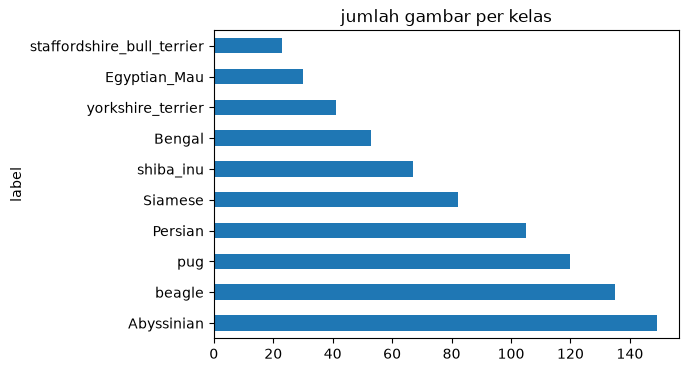

In [6]:
counts = train[TARGET].value_counts()
print(counts)
print("jumlah kelas:", len(counts), "| rasio terbanyak/tersedikit:",
      round(counts.max() / counts.min(), 1))
print("id ganda:", train[ID_COL].duplicated().sum(), "| label kosong:", train[TARGET].isna().sum())
counts.plot.barh(figsize=(6, 4), title="jumlah gambar per kelas")
plt.show()

## EDA: file gambar (ada? format asli? ukuran?)
Ekstensi belum tentu benar: `format` dibaca dari isi file. `mode` RGB = berwarna, L = abu-abu,
RGBA = ada transparansi, P = palet (GIF). Semuanya nanti diubah ke RGB.

In [7]:
def image_info(paths):
    rows = []
    for path in paths:
        if not os.path.exists(path):
            rows.append([path, "TIDAK ADA", "", 0, 0])
            continue
        image = Image.open(path)
        rows.append([path, image.format, image.mode, image.width, image.height])
    return pd.DataFrame(rows, columns=["path", "format", "mode", "width", "height"])


train_info = image_info(train["path"])
test_info = image_info(test["path"])
print("format train:", train_info["format"].value_counts().to_dict())
print("format test :", test_info["format"].value_counts().to_dict())
print("mode train:", train_info["mode"].value_counts().to_dict())
print("mode test :", test_info["mode"].value_counts().to_dict())
sizes = pd.DataFrame()
sizes["train_width"] = train_info["width"].describe()
sizes["test_width"] = test_info["width"].describe()
sizes["train_height"] = train_info["height"].describe()
sizes["test_height"] = test_info["height"].describe()
print(sizes.round())
train_info[(train_info["format"] != "JPEG") | (train_info["mode"] != "RGB")]

format train: {'JPEG': 800, 'GIF': 3, 'PNG': 2}
format test : {'JPEG': 268, 'GIF': 1}
mode train: {'RGB': 800, 'P': 3, 'RGBA': 2}
mode test : {'RGB': 267, 'P': 1, 'L': 1}
       train_width  test_width  train_height  test_height
count        805.0       269.0         805.0        269.0
mean         433.0       445.0         388.0        392.0
std          152.0       145.0         143.0        139.0
min          133.0       150.0         150.0        116.0
25%          333.0       334.0         333.0        333.0
50%          500.0       500.0         375.0        375.0
75%          500.0       500.0         500.0        500.0
max         1886.0      1600.0        2606.0       1600.0


,path,format,mode,width,height
68,../../../data_latihan/vision/pets/train/Egyptian_...,GIF,P,300,214
100,../../../data_latihan/vision/pets/train/Egyptian_...,PNG,RGBA,183,275
122,../../../data_latihan/vision/pets/train/Egyptian_...,GIF,P,183,275
126,../../../data_latihan/vision/pets/train/Egyptian_...,GIF,P,246,175
572,../../../data_latihan/vision/pets/train/Abyssinia...,PNG,RGBA,200,150


## EDA: lihat contoh gambar per kelas
Cek dengan mata: apakah label masuk akal, objeknya di tengah, ada gambar aneh/salah label.

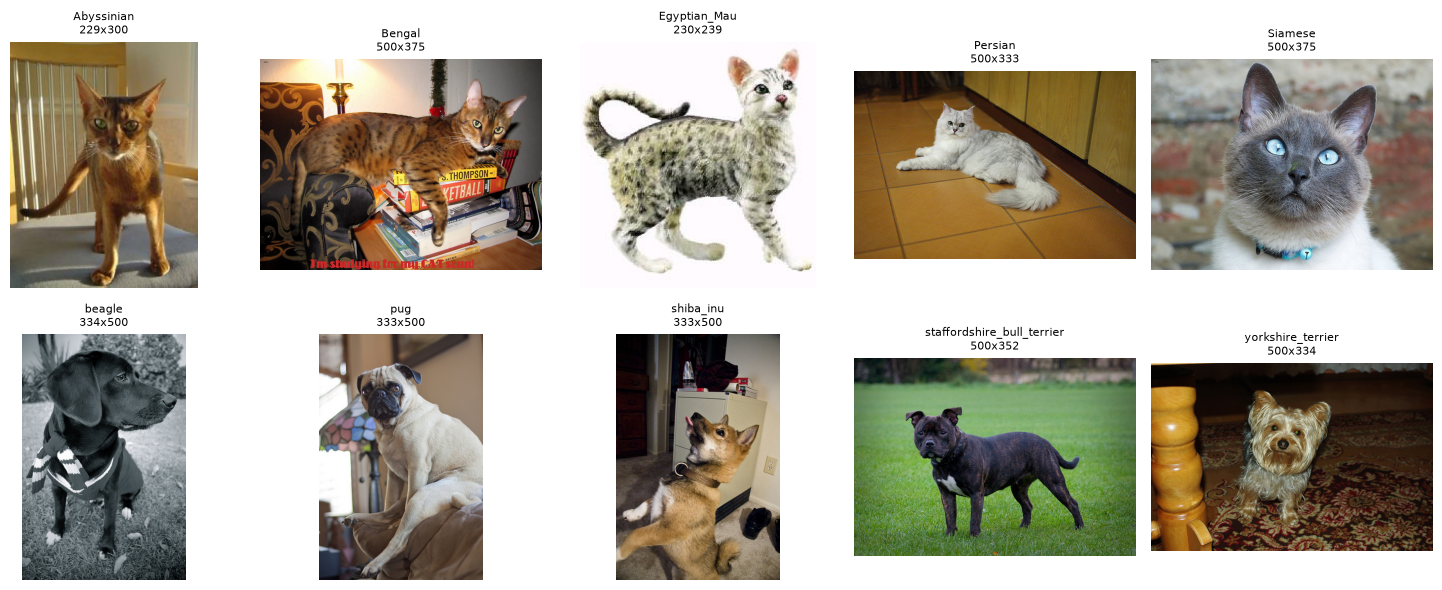

In [8]:
classes = sorted(counts.index)
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax in axes.ravel():
    ax.axis("off")
for ax, class_name in zip(axes.ravel(), classes):
    row = train[train[TARGET] == class_name].iloc[0]
    image = Image.open(row["path"]).convert("RGB")
    ax.imshow(image)
    ax.set_title(f"{class_name}\n{image.width}x{image.height}", fontsize=8)
plt.tight_layout()
plt.show()

## Gambar → tensor
`convert("RGB")` menyamakan semua mode jadi 3 kanal. `ImageOps.fit` memotong bagian tengah
lalu mengecilkan ke persegi `IMAGE_SIZE` (rasio tidak gepeng). Objek sering terpotong di tepi?
Ganti dengan `ImageOps.pad` (menambah bingkai hitam, tidak ada yang terpotong).
Disimpan sebagai uint8 (1 byte/piksel) supaya hemat RAM; dinormalisasi per batch.

In [9]:
def load_images(paths):
    images = np.zeros((len(paths), IMAGE_SIZE, IMAGE_SIZE, 3), dtype=np.uint8)
    for i, path in enumerate(paths):
        image = Image.open(path).convert("RGB")
        images[i] = ImageOps.fit(image, (IMAGE_SIZE, IMAGE_SIZE))
        # images[i] = ImageOps.pad(image, (IMAGE_SIZE, IMAGE_SIZE))
    return torch.tensor(images).permute(0, 3, 1, 2)     # (jumlah, 3, tinggi, lebar)


images_all = load_images(train["path"])
images_test = load_images(test["path"])
print("train:", tuple(images_all.shape), "| test:", tuple(images_test.shape))

train: (805, 3, 224, 224) | test: (269, 3, 224, 224)


## Backbone pretrained beku
Lapisan klasifikasi terakhir diganti `nn.Identity()` supaya keluarannya embedding.
Pilih SATU blok: hapus `#` di blok yang ingin dipakai, beri `#` pada blok resnet50.

In [10]:
backbone = models.resnet50(weights=None)          # embedding 2048 angka
backbone.load_state_dict(torch.load(f"{PRETRAINED}/resnet50/model.pth", map_location="cpu"))
backbone.fc = nn.Identity()

# backbone = models.convnext_tiny(weights=None)   # 768 angka, sering paling bagus
# backbone.load_state_dict(torch.load(f"{PRETRAINED}/convnext_tiny/model.pth"))
# backbone.classifier[2] = nn.Identity()

# backbone = models.vit_b_16(weights=None)        # 768 angka, WAJIB IMAGE_SIZE = 224
# backbone.load_state_dict(torch.load(f"{PRETRAINED}/vit_b_16/model.pth"))
# backbone.heads = nn.Identity()

# backbone = models.efficientnet_b0(weights=None)  # 1280 angka
# backbone.load_state_dict(torch.load(f"{PRETRAINED}/efficientnet_b0/model.pth"))
# backbone.classifier = nn.Identity()

# backbone = models.resnet18(weights=None)        # 512 angka, paling cepat
# backbone.load_state_dict(torch.load(f"{PRETRAINED}/resnet18/model.pth"))
# backbone.fc = nn.Identity()
backbone = backbone.to(DEVICE)
backbone.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

## Embedding semua gambar (+ disimpan ke `.npy`)
Embedding = rata-rata gambar asli dan gambar dibalik kiri-kanan (sedikit lebih stabil).
Jalankan ulang notebook dengan model lain? Muat file `.npy` supaya tidak menghitung ulang.

In [11]:
def embed(images):
    batches = []
    with torch.no_grad():
        for start in range(0, len(images), BATCH_SIZE):
            batch = (images[start:start + BATCH_SIZE].float() / 255 - MEAN) / STD
            batch = batch.to(DEVICE)
            batches.append(((backbone(batch) + backbone(batch.flip(3))) / 2).cpu())
    return torch.cat(batches).numpy()


X_all = embed(images_all)
X_test = embed(images_test)
np.save(f"{OUTPUT_FOLDER}/embedding_train.npy", X_all)
np.save(f"{OUTPUT_FOLDER}/embedding_test.npy", X_test)
# X_all = np.load(f"{OUTPUT_FOLDER}/embedding_train.npy")
# X_test = np.load(f"{OUTPUT_FOLDER}/embedding_test.npy")
print("embedding train:", X_all.shape, "| test:", X_test.shape)

embedding train: (805, 2048) | test: (269, 2048)


## Split train / validasi (stratified)

In [12]:
y_all = train[TARGET].to_numpy()
train_rows, val_rows = train_test_split(np.arange(len(y_all)), test_size=VAL_FRACTION,
                                        stratify=y_all, random_state=SEED)
X_train = X_all[train_rows]
X_val = X_all[val_rows]
y_train = y_all[train_rows]
y_val = y_all[val_rows]
print("train:", X_train.shape, "| validasi:", X_val.shape)

train: (644, 2048) | validasi: (161, 2048)


## Model
Pilih SATU model: hapus `#` di baris yang ingin dipakai. LogisticRegression hampir selalu
baseline terbaik untuk embedding. `C` kecil = lebih sederhana (cegah overfit).

In [13]:
model = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000,
                                                           class_weight="balanced"))
# model = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000))
# model = make_pipeline(StandardScaler(), SVC(C=10, class_weight="balanced", random_state=SEED))
# model = KNeighborsClassifier(n_neighbors=10, metric="cosine")
# model = LGBMClassifier(n_estimators=300, class_weight="balanced", verbose=-1, random_state=SEED)
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](10,)","['Abyssinian','Bengal','Egyptian_Mau',...,'shiba_inu', 'staffordshire_bull_terrier','yorkshire_terrier']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2048
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


## Evaluasi di validasi
Baca confusion matrix: baris = label asli, kolom = tebakan. Angka di luar diagonal = salah.

akurasi: 0.9689
F1 macro: 0.9633
                            precision    recall  f1-score   support

                Abyssinian       0.88      1.00      0.94        30
                    Bengal       1.00      0.73      0.84        11
              Egyptian_Mau       1.00      0.83      0.91         6
                   Persian       0.95      1.00      0.98        21
                   Siamese       1.00      0.94      0.97        16
                    beagle       1.00      1.00      1.00        27
                       pug       1.00      1.00      1.00        24
                 shiba_inu       1.00      1.00      1.00        13
staffordshire_bull_terrier       1.00      1.00      1.00         5
         yorkshire_terrier       1.00      1.00      1.00         8

                  accuracy                           0.97       161
                 macro avg       0.98      0.95      0.96       161
              weighted avg       0.97      0.97      0.97       161



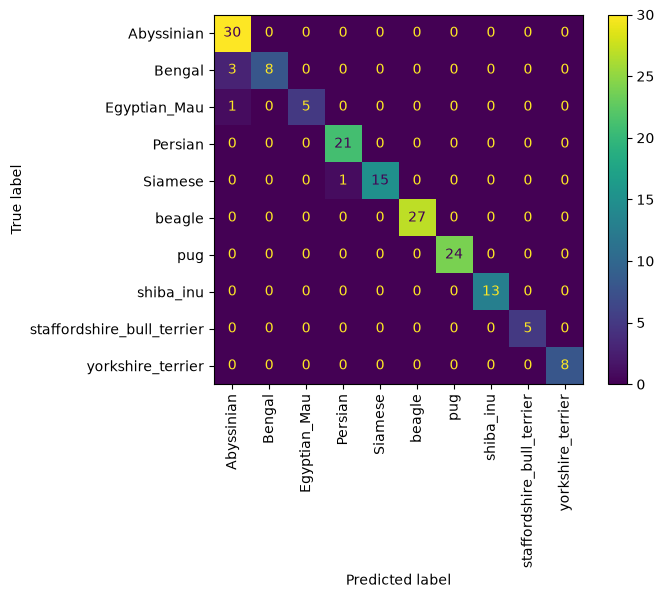

In [14]:
val_predictions = model.predict(X_val)
print("akurasi:", round((val_predictions == y_val).mean(), 4))
print("F1 macro:", round(f1_score(y_val, val_predictions, average="macro"), 4))
print(classification_report(y_val, val_predictions))
ConfusionMatrixDisplay.from_predictions(y_val, val_predictions, xticks_rotation=90)
plt.show()

## Cross-validation 5 fold (skor lebih stabil daripada satu split)
Pakai ini untuk membandingkan model/backbone: satu split validasi kecil bisa beruntung.

In [15]:
folds = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
scores = cross_val_score(model, X_all, y_all, cv=folds, scoring="f1_macro")
print("F1 macro per fold:", scores.round(4))
print("rata-rata:", round(scores.mean(), 4), "| simpangan:", round(scores.std(), 4))

F1 macro per fold: [0.9758 0.9565 0.9484 0.9638 0.9599]
rata-rata: 0.9609 | simpangan: 0.009


## Lihat gambar yang salah tebak

salah: 5 dari 161


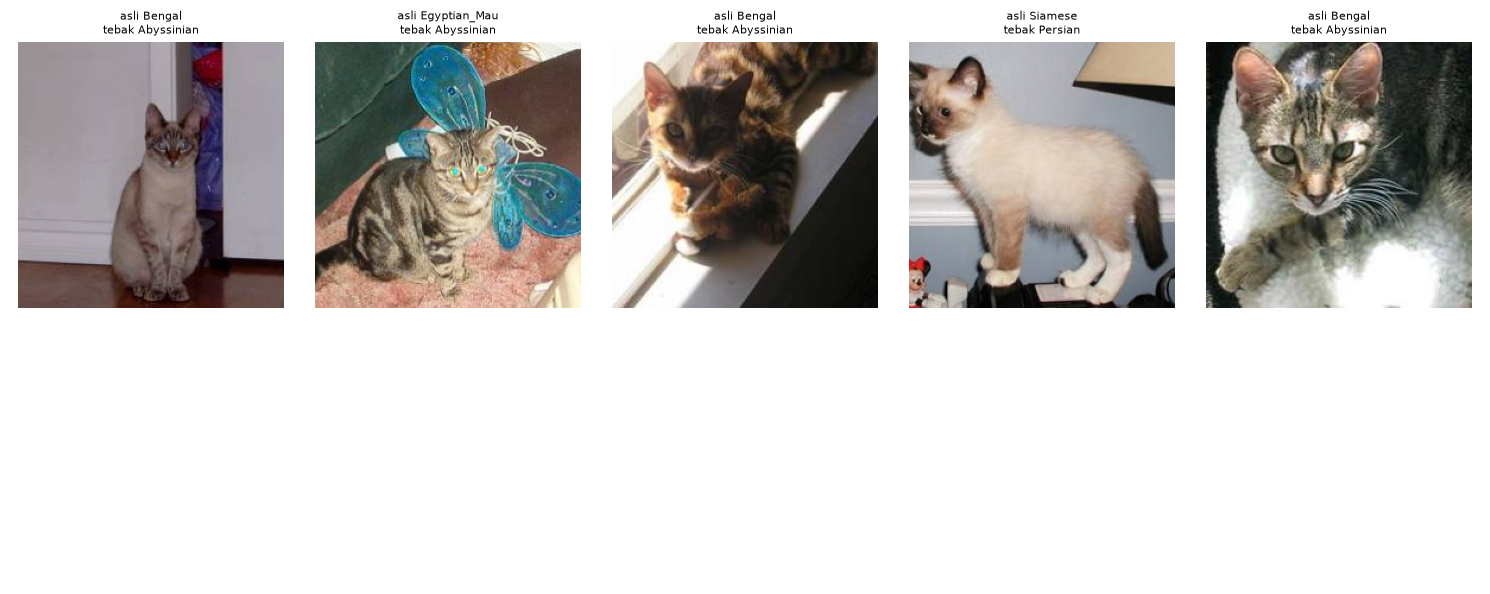

In [16]:
wrong_rows = val_rows[val_predictions != y_val]
print("salah:", len(wrong_rows), "dari", len(val_rows))
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax in axes.ravel():
    ax.axis("off")
for ax, row in zip(axes.ravel(), wrong_rows):
    predicted = model.predict(X_all[row:row + 1])[0]
    ax.imshow(images_all[row].permute(1, 2, 0).numpy())
    ax.set_title(f"asli {y_all[row]}\ntebak {predicted}", fontsize=8)
plt.tight_layout()
plt.show()

## Latih ulang di SEMUA data train, lalu submission
Format kolom harus sama dengan `sample_submission.csv` (di sini `id,label`).

In [17]:
model.fit(X_all, y_all)
predictions = model.predict(X_test)

submission = pd.DataFrame()
submission[ID_COL] = test[ID_COL]
submission[TARGET] = predictions
submission.to_csv(f"{OUTPUT_FOLDER}/submission.csv", index=False)
print(submission.shape)
print(submission[TARGET].value_counts())
submission.head()

(269, 2)
label
Abyssinian                    50
beagle                        45
pug                           40
Persian                       35
Siamese                       28
shiba_inu                     23
Bengal                        17
yorkshire_terrier             14
Egyptian_Mau                  10
staffordshire_bull_terrier     7
Name: count, dtype: int64


,id,label
0,test_0001.jpg,pug
1,test_0002.jpg,Egyptian_Mau
2,test_0003.jpg,shiba_inu
3,test_0004.jpg,Abyssinian
4,test_0005.jpg,Siamese


## Cek dengan kunci jawaban latihan (HAPUS saat lomba)

In [18]:
test_key = pd.read_csv(TEST_KEY_CSV)
print("urutan id sama:", (test_key["id"] == submission[ID_COL]).all())
print("F1 macro test:", round(f1_score(test_key["label"], predictions, average="macro"), 4))

urutan id sama: True
F1 macro test: 0.9842


## Masalah umum
- **`FileNotFoundError`:** lihat `contoh path` di sel Baca data. Biasanya `IMAGE_EXTENSION` atau
  nama folder salah. Tabel EDA file menandai `TIDAK ADA`.
- **`UnidentifiedImageError: cannot identify image file`:** file rusak. Cari di tabel EDA file,
  lalu buang barisnya: `train = train[train["path"] != "<path rusak>"]`.
- **`The least populated class in y has only 1 member`:** ada kelas dengan 1 gambar; stratify
  gagal. Buang `stratify=` atau gabungkan kelas langka.
- **`ConvergenceWarning` LogisticRegression:** naikkan `max_iter` atau perkecil `C`.
- **`size mismatch` saat `load_state_dict`:** blok backbone dan folder bobot tidak cocok.
- **Skor stuck rendah:** coba backbone lain (convnext_tiny), lalu `klasifikasi_cnn` (fine-tune).
- **Submission ditolak:** cek nama kolom, jumlah baris, dan format id persis `sample_submission`.